<a href="https://colab.research.google.com/github/LauWata/SPRINT7LauraJuan/blob/main/version2_nueva_SPRINT7nivel2ex1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Nivell 2
---------------------------------------------------------------------------
Exercici 1: Gestió de risc i priorització de pacients


Treballes com a analista de dades en un centre mèdic especialitzat. Diversos pacients han enviat els seus símptomes a través d'un formulari online, però les dades arriben en un format desordenat i poc estructurat, i l'equip mèdic necessita que els organitzis per poder prioritzar l'ordre d'atenció segons la gravetat.


A continuació tens una llista amb informació real procedent del sistema:


    pacients = [
    
    "Maria|45|tos, Fiebre Alta, dolor_pecho",

    "Luis|33|dolor_cabeza,faTiga",

    "Sara|67|fiebre alta, dificultad RESPIRAR, tos",

    "Jordi|52|fatiga , tos",

    "Anna|29|fiebre alta,dolor_cabeza" ]

El departament mèdic també t'ha proporcionat el següent diccionari de nivells de risc per símptoma:

    nivells_risc = {

    "fiebre_alta": 3,

    "dificultad_respirar": 5,

    "dolor_pecho": 4,

    "tos": 1,

    "fatiga": 1,

    "dolor_cabeza": 1 }


🎯 Objectius
---------------------------------------------------------------
--------------------------------------------------------------
L'objectiu és transformar aquestes dades en informació útil per als metges. A partir dels registres en brut, has de:

» Convertir cada string en una estructura neta (diccionari o similar).

» Separar i normalitzar la llista de símptomes: minúscules eliminar espais dividir correctament per comes

» Assignar un risc a cada símptoma utilitzant el diccionari nivells_risc.

» Calcular el risc total de cada pacient sumant els valors.

» Ordenar els pacients de major a menor risc per determinar la prioritat d'atenció.
    


✅ Resultat esperat
----------------------------------------------------------------------------
--------------------------------------------------------------------------------

Un DataFrame o un diccionari amb:

nom

edat

símptomes normalitzats

risc_total

I un apartat final amb els pacients ordenats per prioritat (més risc → primer).


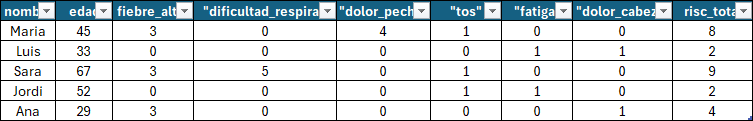

ADJUNTO EN EXCEL EL ESQUEMA QUE HE PENSADO PARA SEPARAR Y ASIGNAR LOS VALORES:

he realizado 2 versiones anteriores, pero esta es la definitiva


la primera fase de debo realizar es una limpiezaa de la lista de los datos, sin tocar el elemento |. (#funcion limpieza de datos de la lista) seguire teniendo lista

la segunda fase tendre una lista de valores usare replace para crear una lista anidada




In [225]:
pacients = [

"Maria|45|tos, Fiebre Alta, dolor_pecho",

"Luis|33|dolor_cabeza,faTiga",

"Sara|67|fiebre alta, dificultad RESPIRAR, tos",

"Jordi|52|fatiga , tos",

"Anna|29|fiebre alta,dolor_cabeza" ]


nivells_risc = {

"fiebre_alta": 3,

"dificultad_respirar": 5,

"dolor_pecho": 4,

"tos": 1,

"fatiga": 1,

"dolor_cabeza": 1 }

In [226]:
#funcion limpieza de datos de la lista
def limpiar(pacients):
  lista_pacientes=[]
  for texto in pacients:
    texto_limpio=texto.lower().replace("_"," ").replace(",","|").strip()
    lista_pacientes.append(texto_limpio)
  return lista_pacientes
lista_pacientes=limpiar(pacients)
print(lista_pacientes)

['maria|45|tos| fiebre alta| dolor pecho', 'luis|33|dolor cabeza|fatiga', 'sara|67|fiebre alta| dificultad respirar| tos', 'jordi|52|fatiga | tos', 'anna|29|fiebre alta|dolor cabeza']


In [227]:
#funcion separar la lista por pacientes
def separar(lista_pacientes):
  lista_pacientesv2=[]
  for paciente in lista_pacientes:
    paciente=paciente.strip()
    pacientev2= paciente.split("|") # separar mediante split no sabia que split
    pacientev3 = []

    for valores in pacientev2:
      valor_limpio = valores.strip()
      pacientev3.append(valor_limpio)
    lista_pacientesv2.append(pacientev3)
  return lista_pacientesv2

lista_pacientesv2=separar(lista_pacientes)

print(lista_pacientesv2)



[['maria', '45', 'tos', 'fiebre alta', 'dolor pecho'], ['luis', '33', 'dolor cabeza', 'fatiga'], ['sara', '67', 'fiebre alta', 'dificultad respirar', 'tos'], ['jordi', '52', 'fatiga', 'tos'], ['anna', '29', 'fiebre alta', 'dolor cabeza']]


In [228]:
#crear un diccionario con id pacientes y sus sintomas puntuados
def crear_dic_pacientes(lista_pacientesv2):
  dic_todospacientes = {}
  id_paciente = 0

  for paciente in lista_pacientesv2:
    dic_paciente ={}

    dic_paciente["Nombre"]= paciente[0]

    dic_paciente["Edad"]= paciente[1]

    dic_paciente["Resum:sintomas"]= paciente[2:]

    if "fiebre alta" in paciente:
      dic_paciente["fiebre_alta"] = nivells_risc['fiebre_alta']
    else:
      dic_paciente["fiebre_alta"] = 0
    if "dolor pecho" in paciente:
      dic_paciente["dolor_pecho"] = nivells_risc['dolor_pecho']
    else:
      dic_paciente["dolor_pecho"] = 0
    if "dolor cabeza" in paciente:
      dic_paciente["dolor_cabeza"] = nivells_risc['dolor_cabeza']
    else:
      dic_paciente["dolor_cabeza"] = 0
    if "dificultad respirar" in paciente:
      dic_paciente["dificultad_respirar"] = nivells_risc['dificultad_respirar']
    else:
      dic_paciente["dificultad_respirar"] = 0
    if "tos" in paciente:
      dic_paciente["tos"] = nivells_risc['tos']
    else:
      dic_paciente["tos"] = 0
    if "fatiga" in paciente:
      dic_paciente["fatiga"] = nivells_risc['fatiga']
    else:
      dic_paciente["fatiga"] = 0

    id_paciente = id_paciente + 1
    dic_todospacientes[id_paciente]=dic_paciente

  return dic_todospacientes

dic_todospacientes = crear_dic_pacientes(lista_pacientesv2)
print(dic_todospacientes)


{1: {'Nombre': 'maria', 'Edad': '45', 'Resum:sintomas': ['tos', 'fiebre alta', 'dolor pecho'], 'fiebre_alta': 3, 'dolor_pecho': 4, 'dolor_cabeza': 0, 'dificultad_respirar': 0, 'tos': 1, 'fatiga': 0}, 2: {'Nombre': 'luis', 'Edad': '33', 'Resum:sintomas': ['dolor cabeza', 'fatiga'], 'fiebre_alta': 0, 'dolor_pecho': 0, 'dolor_cabeza': 1, 'dificultad_respirar': 0, 'tos': 0, 'fatiga': 1}, 3: {'Nombre': 'sara', 'Edad': '67', 'Resum:sintomas': ['fiebre alta', 'dificultad respirar', 'tos'], 'fiebre_alta': 3, 'dolor_pecho': 0, 'dolor_cabeza': 0, 'dificultad_respirar': 5, 'tos': 1, 'fatiga': 0}, 4: {'Nombre': 'jordi', 'Edad': '52', 'Resum:sintomas': ['fatiga', 'tos'], 'fiebre_alta': 0, 'dolor_pecho': 0, 'dolor_cabeza': 0, 'dificultad_respirar': 0, 'tos': 1, 'fatiga': 1}, 5: {'Nombre': 'anna', 'Edad': '29', 'Resum:sintomas': ['fiebre alta', 'dolor cabeza'], 'fiebre_alta': 3, 'dolor_pecho': 0, 'dolor_cabeza': 1, 'dificultad_respirar': 0, 'tos': 0, 'fatiga': 0}}


In [229]:
# CALCULAR RIESGO Y CREAR EL DICCIONARIO FINAL CON LA VISION DESEADA


def calcular_risc(dic_todospacientes):

  dic_pacientes_final = {}
  for id_paciente,paciente in dic_todospacientes.items():
    paciente_final = {}

    calcul_risc= paciente['dificultad_respirar']+paciente['dolor_cabeza']+paciente['dolor_pecho']+paciente['fatiga']+paciente['fiebre_alta']+paciente['tos']

    paciente_final["NOMBRE"]=paciente['Nombre']
    paciente_final["EDAD"]=paciente['Edad']
    paciente_final["SINTOMATOLOGIA"]=paciente['Resum:sintomas']
    paciente_final["RISC_TOTAL"]=calcul_risc

    dic_pacientes_final[id_paciente]=paciente_final
  return dic_pacientes_final

dic_pacientes_final=calcular_risc(dic_todospacientes)

print(dic_pacientes_final)



{1: {'NOMBRE': 'maria', 'EDAD': '45', 'SINTOMATOLOGIA': ['tos', 'fiebre alta', 'dolor pecho'], 'RISC_TOTAL': 8}, 2: {'NOMBRE': 'luis', 'EDAD': '33', 'SINTOMATOLOGIA': ['dolor cabeza', 'fatiga'], 'RISC_TOTAL': 2}, 3: {'NOMBRE': 'sara', 'EDAD': '67', 'SINTOMATOLOGIA': ['fiebre alta', 'dificultad respirar', 'tos'], 'RISC_TOTAL': 9}, 4: {'NOMBRE': 'jordi', 'EDAD': '52', 'SINTOMATOLOGIA': ['fatiga', 'tos'], 'RISC_TOTAL': 2}, 5: {'NOMBRE': 'anna', 'EDAD': '29', 'SINTOMATOLOGIA': ['fiebre alta', 'dolor cabeza'], 'RISC_TOTAL': 4}}


In [230]:
# funcion ordenar el diccionario

def ordenar(dic_pacientes_final):

  lista_pacientes_final_ordenado = sorted(dic_pacientes_final.items(), key=lambda item: item[1]['RISC_TOTAL'], reverse=True)


  dic_pacientes_final_ordenado = {}
  for paciente in lista_pacientes_final_ordenado:

    dic_pacientes_final_ordenado[paciente[0]] = paciente [1]


  return dic_pacientes_final_ordenado

dic_pacientes_final_ordenado = ordenar(dic_pacientes_final)
print(dic_pacientes_final_ordenado)



{3: {'NOMBRE': 'sara', 'EDAD': '67', 'SINTOMATOLOGIA': ['fiebre alta', 'dificultad respirar', 'tos'], 'RISC_TOTAL': 9}, 1: {'NOMBRE': 'maria', 'EDAD': '45', 'SINTOMATOLOGIA': ['tos', 'fiebre alta', 'dolor pecho'], 'RISC_TOTAL': 8}, 5: {'NOMBRE': 'anna', 'EDAD': '29', 'SINTOMATOLOGIA': ['fiebre alta', 'dolor cabeza'], 'RISC_TOTAL': 4}, 2: {'NOMBRE': 'luis', 'EDAD': '33', 'SINTOMATOLOGIA': ['dolor cabeza', 'fatiga'], 'RISC_TOTAL': 2}, 4: {'NOMBRE': 'jordi', 'EDAD': '52', 'SINTOMATOLOGIA': ['fatiga', 'tos'], 'RISC_TOTAL': 2}}


In [231]:
def mostrar_informe_prioritarios(dic_pacientes_final_ordenado):
  print("\n"
        "-----------------------------------------------\n"
        "INFORME LISTA PACIENTES POR ORDEN DE PRIORIDAD \n"
         "-----------------------------------------------\n")
  for id,paciente in dic_pacientes_final_ordenado.items():
    informe = print("\n"
        "DATOS DEL PACIENTE\n"
        "-----------------------------------------------\n"
        f"NOMBRE; {paciente['NOMBRE']}\n"
      f"EDAD; {paciente['EDAD']}\n"
      f"SINTOMATOLOGIA;  {paciente['SINTOMATOLOGIA']}\n"
      f"RISC_TOTAL; {paciente['RISC_TOTAL']}")

  return informe

informe = mostrar_informe_prioritarios(dic_pacientes_final_ordenado)
print(informe)





-----------------------------------------------
INFORME LISTA PACIENTES POR ORDEN DE PRIORIDAD 
-----------------------------------------------


DATOS DEL PACIENTE
-----------------------------------------------
NOMBRE; sara
EDAD; 67
SINTOMATOLOGIA;  ['fiebre alta', 'dificultad respirar', 'tos']
RISC_TOTAL; 9

DATOS DEL PACIENTE
-----------------------------------------------
NOMBRE; maria
EDAD; 45
SINTOMATOLOGIA;  ['tos', 'fiebre alta', 'dolor pecho']
RISC_TOTAL; 8

DATOS DEL PACIENTE
-----------------------------------------------
NOMBRE; anna
EDAD; 29
SINTOMATOLOGIA;  ['fiebre alta', 'dolor cabeza']
RISC_TOTAL; 4

DATOS DEL PACIENTE
-----------------------------------------------
NOMBRE; luis
EDAD; 33
SINTOMATOLOGIA;  ['dolor cabeza', 'fatiga']
RISC_TOTAL; 2

DATOS DEL PACIENTE
-----------------------------------------------
NOMBRE; jordi
EDAD; 52
SINTOMATOLOGIA;  ['fatiga', 'tos']
RISC_TOTAL; 2
None


In [232]:
def main_prioridad():
  lista_pacientes=limpiar(pacients)
  lista_pacientesv2=separar(lista_pacientes)
  dic_todospacientes = crear_dic_pacientes(lista_pacientesv2)
  dic_pacientes_final=calcular_risc(dic_todospacientes)
  dic_pacientes_final_ordenado = ordenar(dic_pacientes_final)
  informe = mostrar_informe_prioritarios(dic_pacientes_final_ordenado)




In [234]:
main_prioridad()


-----------------------------------------------
INFORME LISTA PACIENTES POR ORDEN DE PRIORIDAD 
-----------------------------------------------


DATOS DEL PACIENTE
-----------------------------------------------
NOMBRE; sara
EDAD; 67
SINTOMATOLOGIA;  ['fiebre alta', 'dificultad respirar', 'tos']
RISC_TOTAL; 9

DATOS DEL PACIENTE
-----------------------------------------------
NOMBRE; maria
EDAD; 45
SINTOMATOLOGIA;  ['tos', 'fiebre alta', 'dolor pecho']
RISC_TOTAL; 8

DATOS DEL PACIENTE
-----------------------------------------------
NOMBRE; anna
EDAD; 29
SINTOMATOLOGIA;  ['fiebre alta', 'dolor cabeza']
RISC_TOTAL; 4

DATOS DEL PACIENTE
-----------------------------------------------
NOMBRE; luis
EDAD; 33
SINTOMATOLOGIA;  ['dolor cabeza', 'fatiga']
RISC_TOTAL; 2

DATOS DEL PACIENTE
-----------------------------------------------
NOMBRE; jordi
EDAD; 52
SINTOMATOLOGIA;  ['fatiga', 'tos']
RISC_TOTAL; 2
